# 06b - Recurrent and Interactive Prediction

## Imports

In [ ]:
import warnings
# Same benign numpy 2.x + Apple Accelerate matmul quirk noted in 06; no actual NaN/Inf in any result
warnings.filterwarnings('ignore', category=RuntimeWarning)

import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.nn.utils.rnn import pack_padded_sequence

np.random.seed(1515)
torch.manual_seed(1515)

## Where 06 Left Off

`06-trajectory-prediction.ipynb` gave a model a fixed history window of the last $K$ positions and asked it to predict the next $M$. It beat constant velocity because it could see curvature, but it closed that notebook with two limits we cover in-depth in this notebook. 

### Memory 
A window is exactly $K$ steps long, and that is determined before we ever see any model information. We have to pick 3 steps vs. 50 before ever seeing live movement, which naturally creates constraints on how much information we can take from that prediction. 

### Interaction 
The model can only see the opponent's own past. Meaning, we only guess what our opponent is doing for its trajectories based on trajectories we have already observed. However, recall from `05-objects-in-motion.ipynb` that any object trajectory can change for random reasons, like a ball hitting another ball or a robot spinning out of control. If something else on the field, besides the team's (intentional) decisions, makes the robot move, the model can't really predict the next turn because it is working with irrelevant information. 


The models that lie between windowed networks like we just covered and Transformers cover both of these concerns. **Recurrent networks** (RNNs, LSTMs, GRUs) handle the memory problem. **Social pooling**, which motivates Social LSTM models, handles the second. 

Transformers and attention (see `genai_primer` for more on this) will close the remaining weakness of recurrent models, to be covered shortly. 

## Backpropagation in PyTorch

On another note, this notebook uses PyTorch for training, unlike the hand-written backpropagation we've been using. Backpropagation through a recurrent network (called backpropagation *through time*) is the same chain rule from `deep_learning_primer/01`, just unrolled over every time step, and it's tedious enough that real systems will let **autograd**, or an automatic gradient calculation, do the work for them. 

We'll still build the forward mechanics of both the RNN and the LSTM by hand first so you can see everything autograd is doing for you. 

## A Scene With More Than One Robot

Time to upgrade 06's dataset. Each scene now has an **opponent** we're trying to predict, plus up to three **defenders** (some combination of our two alliance teammates and the other two opponents) moving through the same space. The opponent's motion follows three rules:

1. It drives towards a hidden goal and has inertia, meaning its velocity relazes toward the direction of the goal instead of sharply moving to it. This gives us a smooth curve.
2. Speed is not constant, meaning it speeds up and slows down on a pre-set stop-and-go profile. 
3. It is repelled by nearby defenders. If a defender gets close, it swerves away. We have two kinds of defenders, one of which will cross the opponent's path (which is what matters because it will disrupt the predicted path), or others that just wander (distractions).

This is the "knocked off course by another robot" scenario from `05`. We build it such a way so that the cause of a swerve is visible in the *defenders'* positions, not in the opponent's own history (at least until the swerve has already started)

We observe everyone's positions through noisy sensors, like before. Every model sees the same 12 observed steps and predicts the next 8 positions of the opponent only.

In [2]:
DT = 0.1          # seconds per tick
T_HIST = 12       # observed steps the model gets to see
M = 8             # prediction horizon (future steps to predict)
MAX_N = 3         # up to this many defenders per scene
NOISE = 0.03      # sensor noise on every observed position

def generate_scene(rng, max_n=MAX_N):
    """One scene: an opponent heading for a hidden goal, plus 0..max_n defenders it swerves around."""
    total = T_HIST + M
    goal_dir = rng.uniform(0, 2 * np.pi)
    goal = rng.uniform(4, 8) * np.array([np.cos(goal_dir), np.sin(goal_dir)])
    base_speed = rng.uniform(1.0, 2.0)
    amp, freq, phase = rng.uniform(0.2, 0.5), rng.uniform(1.5, 4.0), rng.uniform(0, 2 * np.pi)

    pos = np.zeros(2)
    vel = goal / np.linalg.norm(goal) * base_speed * rng.uniform(0.3, 1.0)

    n_def = rng.integers(0, max_n + 1)
    defenders = []
    for _ in range(n_def):
        if rng.random() < 0.6:
            # a defender aimed to pass near where the opponent is about to be
            t_meet = rng.uniform(1.0, 2.0)
            meet_point = goal / np.linalg.norm(goal) * base_speed * t_meet * 0.8 + rng.normal(0, 0.3, 2)
            angle, speed = rng.uniform(0, 2 * np.pi), rng.uniform(1.0, 2.0)
            d_vel = speed * np.array([np.cos(angle), np.sin(angle)])
            d_start = meet_point - d_vel * t_meet
        else:
            # a distractor: wanders at random
            d_start, d_vel = rng.uniform(-6, 6, 2), rng.uniform(-1.5, 1.5, 2)
        defenders.append((d_start, d_vel))

    opp = np.zeros((total, 2))
    defs = np.zeros((total, max_n, 2))
    present = np.zeros((total, max_n))        # 1 where a defender slot is actually occupied
    for t in range(total):
        opp[t] = pos
        for k, (d_start, d_vel) in enumerate(defenders):
            defs[t, k] = d_start + d_vel * t * DT
            present[t, k] = 1

        speed_now = base_speed * (1 + amp * np.sin(freq * t * DT + phase))
        to_goal = goal - pos
        desired_vel = speed_now * to_goal / (np.linalg.norm(to_goal) + 1e-6)
        accel = (desired_vel - vel) / 0.5                         # inertia: relax toward desired velocity
        for k in range(len(defenders)):
            away = pos - defs[t, k]
            dist = np.linalg.norm(away) + 1e-6
            accel += 12.0 * np.exp(-dist / 0.8) * away / dist     # repulsion from defender k
        vel = vel + accel * DT
        pos = pos + vel * DT

    # smallest distance between the opponent and any defender during the prediction horizon
    gap = 9.0
    for k in range(len(defenders)):
        gap = min(gap, np.min(np.linalg.norm(opp[T_HIST:] - defs[T_HIST:, k], axis=1)))

    return dict(
        opp=opp + rng.normal(0, NOISE, opp.shape),
        defs=defs + rng.normal(0, NOISE, defs.shape),
        present=present, gap=gap, clean_opp=opp, clean_defs=defs,
    )

def make_dataset(n, seed, max_n=MAX_N):
    """Everything is expressed relative to the opponent's most recent observed position, as in 06."""
    rng = np.random.default_rng(seed)
    scenes = [generate_scene(rng, max_n) for _ in range(n)]
    opp = np.array([s['opp'] for s in scenes])
    defs = np.array([s['defs'] for s in scenes])
    present = np.array([s['present'] for s in scenes])
    anchor = opp[:, T_HIST - 1:T_HIST, :]

    opp_hist = opp[:, :T_HIST] - anchor                                   # (n, T_HIST, 2)
    nbr_hist = (defs[:, :T_HIST] - anchor[:, :, None, :]) * present[:, :T_HIST, :, None]   # (n, T_HIST, max_n, 2)
    nbr_mask = present[:, :T_HIST]                                        # (n, T_HIST, max_n)
    future = (opp[:, T_HIST:] - anchor).reshape(n, -1)                    # (n, 2*M)
    gap = np.array([s['gap'] for s in scenes])
    as_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return dict(opp=as_t(opp_hist), nbr=as_t(nbr_hist), mask=as_t(nbr_mask), future=as_t(future), gap=as_t(gap))

train = make_dataset(8000, seed=1)
test = make_dataset(1000, seed=2)
interacting = test['gap'] < 1.0     # a defender comes within 1.0 of the opponent during the horizon
print(f"train opp history: {tuple(train['opp'].shape)}, neighbors: {tuple(train['nbr'].shape)}, future: {tuple(train['future'].shape)}")
print(f"Test scenes where a defender gets close during the horizon: {interacting.float().mean():.0%}")

train opp history: (8000, 12, 2), neighbors: (8000, 12, 3, 2), future: (8000, 16)
Test scenes where a defender gets close during the horizon: 34%


Let's look at one scene where a defender really does cut across the opponent's path. We'll plot the noiseless ground truth so the geometry is easy to see.

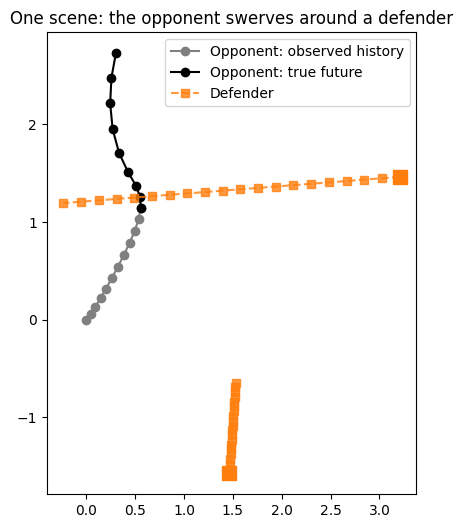

In [3]:
scene_rng = np.random.default_rng(11)
while True:
    scene = generate_scene(scene_rng)
    if 0.3 < scene['gap'] < 0.8:
        break

fig, ax = plt.subplots(figsize=(6, 6))
opp = scene['clean_opp']
ax.plot(opp[:T_HIST, 0], opp[:T_HIST, 1], 'o-', color='gray', label='Opponent: observed history')
ax.plot(opp[T_HIST - 1:, 0], opp[T_HIST - 1:, 1], 'o-', color='black', label='Opponent: true future')
for k in range(MAX_N):
    if scene['present'][0, k]:
        d = scene['clean_defs'][:, k]
        ax.plot(d[:, 0], d[:, 1], 's--', color='tab:orange', alpha=0.8, label='Defender' if k == 0 else None)
        ax.plot(d[0, 0], d[0, 1], 's', color='tab:orange', markersize=10)
ax.set_aspect('equal')
ax.set_title("One scene: the opponent swerves around a defender")
ax.legend()
plt.show()

Notice that the opponent's own history (gray) looks like a steady, straight drive. Nothing in it says "turn." The reason it bends away in the black future segment is on the orange path, which the window-only model from 06 never gets to look at.

## Baselines

Two things to beat. The first is 06's constant-velocity baseline. The second is a feedforward network that reads the last $K = 5$ positions of the *opponent only* (what we built in 06). We'll score everything with 06's ADE and FDE, and, since we care about the interaction cases specifically, we'll also report them split by whether a defender came close during the horizon.

In [4]:
def displacement_errors(pred, future):
    """Per-example, per-step Euclidean error: shape (n, M)."""
    return (pred - future).reshape(-1, M, 2).norm(dim=2)

def evaluate(pred, data=test):
    err = displacement_errors(pred, data['future'])
    near = data['gap'] < 1.0
    return dict(ade=err.mean().item(), fde=err[:, -1].mean().item(),
                ade_near=err[near].mean().item(), ade_far=err[~near].mean().item())

def constant_velocity(opp):
    velocity = opp[:, -1] - opp[:, -2]
    steps = torch.arange(1, M + 1).float()[None, :, None]
    return (velocity[:, None, :] * steps).reshape(len(opp), -1)

results = {}
results['Constant velocity'] = evaluate(constant_velocity(test['opp']))

def fit(model, data=train, epochs=40, lr=3e-3, seed=0):
    """Same recipe for every model: Adam, mean squared error on the future offsets, cosine LR decay."""
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    n = len(data['opp'])
    for _ in range(epochs):
        order = torch.randperm(n)
        for i in range(0, n, 128):
            idx = order[i:i + 128]
            loss = ((model(data['opp'][idx], data['nbr'][idx], data['mask'][idx]) - data['future'][idx]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
    return model.eval()

def n_params(model):
    return sum(p.numel() for p in model.parameters())

class WindowMLP(nn.Module):
    """06's model: a feedforward net over the last K positions of the opponent only."""
    def __init__(self, K=5):
        super().__init__()
        self.K = K
        self.net = nn.Sequential(nn.Linear(2 * K, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2 * M))
    def forward(self, opp, nbr, mask):
        return self.net(opp[:, -self.K:].reshape(len(opp), -1))

window_mlp = fit(WindowMLP(K=5))
with torch.no_grad():
    results['Window MLP (K=5)'] = evaluate(window_mlp(test['opp'], test['nbr'], test['mask']))
for name, r in results.items():
    print(f"{name:20s} ADE={r['ade']:.3f}  FDE={r['fde']:.3f}   ADE when interacting={r['ade_near']:.3f}, not={r['ade_far']:.3f}")

Constant velocity    ADE=0.329  FDE=0.602   ADE when interacting=0.405, not=0.291
Window MLP (K=5)     ADE=0.235  FDE=0.447   ADE when interacting=0.347, not=0.178


## Memory: Recurrent Networks

### The Hidden State

Instead of flattening the history into one big input vector, a **Recurrent Neural Network (RNN)** reads it one step at a time and carries a **hidden state** $h_t$, a vector that's meant to summarize everything it's seen so far. At each step it combines the new observation $x_t$ with the previous hidden state to produce the next one:

$$h_t = \tanh(W_{xh}\, x_t + W_{hh}\, h_{t-1} + b)$$

The same weights $W_{xh}$, $W_{hh}$ are reused at *every* step. Notice the number of weights doesn't depend on how long the track is, so the same network can read 3 steps or 300. Let's run one by hand on the opponent's observed history from the scene above. The weights here are random (untrained), so the numbers themselves mean nothing; we just want to watch the hidden state evolve.

In [5]:
rng_demo = np.random.default_rng(0)
hidden_size = 4
W_xh = rng_demo.normal(0, 0.5, (hidden_size, 2))
W_hh = rng_demo.normal(0, 0.5, (hidden_size, hidden_size))
b_h = np.zeros(hidden_size)

def rnn_step(x_t, h_prev):
    return np.tanh(W_xh @ x_t + W_hh @ h_prev + b_h)

track = scene['opp'][:T_HIST] - scene['opp'][T_HIST - 1]      # the opponent's observed history, relative to its last position
h = np.zeros(hidden_size)                                    # before seeing anything, the state is empty
for t, x_t in enumerate(track):
    h = rnn_step(x_t, h)
    print(f"step {t + 1:2d}: x=({x_t[0]:+.2f}, {x_t[1]:+.2f})  ->  h={np.round(h, 2)}")

step  1: x=(-0.54, -1.20)  ->  h=[ 0.05 -0.23 -0.07 -0.73]
step  2: x=(-0.57, -1.11)  ->  h=[ 0.17  0.04 -0.4  -0.82]
step  3: x=(-0.49, -1.10)  ->  h=[ 0.06  0.12 -0.56 -0.68]
step  4: x=(-0.44, -0.97)  ->  h=[ 0.1   0.31 -0.51 -0.54]
step  5: x=(-0.40, -0.90)  ->  h=[-0.05  0.19 -0.48 -0.38]
step  6: x=(-0.30, -0.72)  ->  h=[ 0.07  0.33 -0.35 -0.3 ]
step  7: x=(-0.25, -0.66)  ->  h=[-0.1   0.1  -0.34 -0.19]
step  8: x=(-0.17, -0.49)  ->  h=[ 0.09  0.3  -0.2  -0.19]
step  9: x=(-0.13, -0.38)  ->  h=[-0.14 -0.01 -0.24 -0.03]
step 10: x=(-0.04, -0.28)  ->  h=[ 0.15  0.3  -0.07 -0.08]
step 11: x=(-0.05, -0.14)  ->  h=[-0.21 -0.16 -0.15  0.1 ]
step 12: x=(+0.00, +0.00)  ->  h=[ 0.22  0.31  0.1  -0.03]


After the last step, `h` is a fixed-size vector that has been influenced by all 12 observations. A prediction head (an ordinary Regression Head, same as 06) turns that final `h` into the 8 future positions. Everything the model "remembers" about the track has to fit in that one vector.

That is both the idea's strength (any length, constant parameter count) and its weakness, and we'll come back to the weakness at the end of this notebook.

### Why Plain RNNs Struggle: Vanishing Gradients

Training runs on gradients. To learn that step 1's input mattered for a prediction made at step 50, the network needs a learning signal that travels from the loss at step 50 back to step 1. By the chain rule, that signal passes through a product of 49 Jacobians, one per step: $\frac{\partial h_T}{\partial h_t} = \prod_{k=t+1}^{T} \text{diag}(1 - h_k^2)\, W_{hh}$.

If each factor has a typical size $\rho$, the product behaves like $\rho^{T-t}$, and that only has two long-run behaviors:

- **Vanishing ($\rho < 1$).** The product shrinks exponentially toward 0. The $\tanh$ derivative $1 - h_k^2$ is never above 1 (and drops toward 0 when a unit saturates), so it pushes every factor in this direction.
  
- **Exploding ($\rho > 1$).** The product grows exponentially, the gradient balloons to an enormous value, and a single update throws the weights somewhere useless (the loss can jump to something like infinity).

The two failures are not equally bad, because they have different fixes. Exploding gradients are a magnitude problem (the direction is still informative), so **gradient clipping** (rescale the gradient whenever its norm exceeds a threshold) tames them (Pascanu et al., 2013). Vanishing gradients are an information problem because the signal has already been squashed to a size that rounding error can swamp, and scaling it back up mostly amplifies noise. And the consequence is subtle. The network can represent a long memory just fine, since the weights that would hold a value across 50 steps exist. 

What it can't do is learn them, because nothing tells the optimizer that step 1 mattered. The model ends up short-sighted by training, not by design.

So the fix has to be architectural. We give the gradient a route backward that does not pass through a squashing multiplication at every step. Let's measure the problem first.

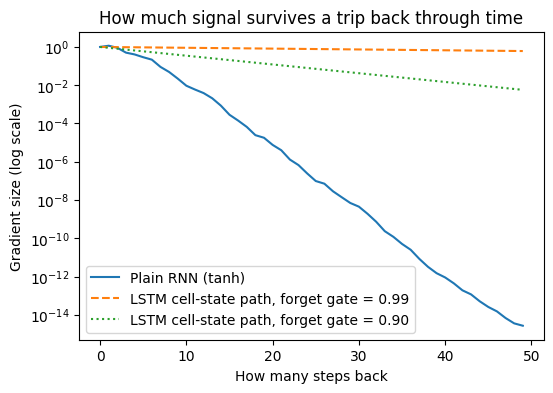

Plain RNN: gradient reaching 30 steps back is 4.5e-09 of what it was at the last step


In [6]:
rng_g = np.random.default_rng(3)
hid, T = 32, 50

W = rng_g.normal(0, 1, (hid, hid))
W *= 0.9 / np.max(np.abs(np.linalg.eigvals(W)))      # spectral radius 0.9: a typical, reasonable-looking initialization
U = rng_g.normal(0, 1, (hid, 2))

h = np.zeros(hid)
hs = []
for t in range(T):
    h = np.tanh(W @ h + U @ rng_g.normal(size=2))
    hs.append(h)

# norm of d h_T / d h_t as we reach further back in time
grad_norm, J = [], np.eye(hid)
for lag in range(T):
    grad_norm.append(np.linalg.norm(J, 2))
    J = J @ (np.diag(1 - hs[T - 1 - lag] ** 2) @ W)

lags = np.arange(T)
plt.figure(figsize=(6, 4))
plt.semilogy(lags, grad_norm, label='Plain RNN (tanh)')
plt.semilogy(lags, 0.99 ** lags, '--', label='LSTM cell-state path, forget gate = 0.99')
plt.semilogy(lags, 0.90 ** lags, ':', label='LSTM cell-state path, forget gate = 0.90')
plt.xlabel('How many steps back')
plt.ylabel('Gradient size (log scale)')
plt.title('How much signal survives a trip back through time')
plt.legend()
plt.show()
print(f"Plain RNN: gradient reaching 30 steps back is {grad_norm[30]:.1e} of what it was at the last step")

The plain RNN's gradient from 30 steps ago is vanishingly small; it can barely learn anything from the far past, even if that past is exactly what it needs.

The fix, the **Long Short-Term Memory (LSTM)** network, adds a second state, the **cell state** $c_t$, that's updated *additively* rather than being squashed through a $\tanh$ at every step:

$$c_t = f_t \odot c_{t-1} + i_t \odot g_t$$

Note the circled dot operator represents a Hadamard, or element-wise, matrix multiplication. See `linear_algebra_primer` if you're unsure about what element-wise multiplication entails. 

Each of $f_t$, $i_t$, and $o_t$ are a sigmoid (between 0 and 1) that are computed from $x_t$ and $h_{t-1}$. 

$f_t$ is the forget gate, which decides how much of the old state to keep. 

$i_t$ is the input gate, which decides how much of the new candidate to write in. 

$o_t$ is the output gate that decides how much of the cell state to expose, written as the hidden state $h_t = o_t \odot \tanh(c_t)$.


When the forget gate stays near 1, the gradient along $c$ is just a product of numbers near 1, which is the dashed line above. It barely decays!

The network *learns* when to hold and when to let go. The plot shows only that one path through the LSTM, and the 0.99 is something the model has to learn rather than a fixed property. But it's the reason LSTMs can reach back through long sequences when plain RNNs can't.

The **Gated Recurrent Unit (GRU)** is a streamlined cousin with two gates and no separate cell state. It performs about the same as an LSTM in most settings and is cheaper to run. We'll use both.

One caveat to keep in mind, because we test it below: the gates are *learned*, and they don't start where the dashed line is. Where a gate starts matters a lot.

Let's build the LSTM cell by hand and check it against PyTorch's. Seeing the four equations match `nn.LSTMCell` shows us that the library layer doesn't actually hide anything.

In [7]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def lstm_step(x_t, h_prev, c_prev, W_ih, W_hh, b):
    z = W_ih @ x_t + W_hh @ h_prev + b                 # all four gates' pre-activations at once
    i, f, g, o = np.split(z, 4)                        # PyTorch's order: input, forget, candidate, output
    i, f, o = sigmoid(i), sigmoid(f), sigmoid(o)
    g = np.tanh(g)
    c = f * c_prev + i * g                             # additive cell-state update
    h = o * np.tanh(c)
    return h, c

torch.manual_seed(0)
torch_cell = nn.LSTMCell(2, 8)
W_ih = torch_cell.weight_ih.detach().numpy()
W_hh_l = torch_cell.weight_hh.detach().numpy()
b_l = (torch_cell.bias_ih + torch_cell.bias_hh).detach().numpy()

h_np, c_np = np.zeros(8), np.zeros(8)
h_t, c_t = torch.zeros(1, 8), torch.zeros(1, 8)
max_diff = 0.0
for x_t in track:
    h_np, c_np = lstm_step(x_t, h_np, c_np, W_ih, W_hh_l, b_l)
    h_t, c_t = torch_cell(torch.tensor(x_t, dtype=torch.float32)[None, :], (h_t, c_t))
    max_diff = max(max_diff, np.abs(h_np - h_t.detach().numpy()[0]).max())
print(f"Largest difference between our hand-built LSTM and nn.LSTMCell over the track: {max_diff:.2e}")

Largest difference between our hand-built LSTM and nn.LSTMCell over the track: 3.14e-08


### Training Recurrent Predictors

Now the real models. Each reads the opponent's full 12-step history through a recurrent layer, takes the final hidden state, and passes it through a Regression Head to produce the 8 future positions, the same head shape as 06's, with a recurrent encoder in front instead of a flattened window. We'll try all three recurrent cells: plain RNN, GRU, and LSTM.

In [8]:
class RecurrentPredictor(nn.Module):
    """Opponent-only history -> recurrent encoder -> final hidden state -> Regression Head."""
    def __init__(self, cell='lstm', hidden=64):
        super().__init__()
        rnn_cls = {'rnn': nn.RNN, 'gru': nn.GRU, 'lstm': nn.LSTM}[cell]
        self.rnn = rnn_cls(2, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, 64), nn.ReLU(), nn.Linear(64, 2 * M))
    def forward(self, opp, nbr, mask):
        states, _ = self.rnn(opp)              # hidden state at every step: (n, T_HIST, hidden)
        return self.head(states[:, -1])        # only the last one feeds the head

models = {}
for cell in ['rnn', 'gru', 'lstm']:
    models[cell] = fit(RecurrentPredictor(cell))
    with torch.no_grad():
        results[f'{cell.upper()} (own history)'] = evaluate(models[cell](test['opp'], test['nbr'], test['mask']))

for name, r in results.items():
    print(f"{name:22s} ADE={r['ade']:.3f}  FDE={r['fde']:.3f}   ADE when interacting={r['ade_near']:.3f}, not={r['ade_far']:.3f}")

Constant velocity      ADE=0.329  FDE=0.602   ADE when interacting=0.405, not=0.291
Window MLP (K=5)       ADE=0.235  FDE=0.447   ADE when interacting=0.347, not=0.178
RNN (own history)      ADE=0.223  FDE=0.431   ADE when interacting=0.318, not=0.175
GRU (own history)      ADE=0.222  FDE=0.429   ADE when interacting=0.316, not=0.174
LSTM (own history)     ADE=0.225  FDE=0.432   ADE when interacting=0.319, not=0.177


This is not the result you might expect from a notebook about recurrence, so it's worth reading carefully. All three recurrent cells beat the window MLP, but only slightly: ADE goes from 0.235 to roughly 0.22, about 5%. And the three cells are essentially indistinguishable from each other (this is one training run each, so differences of a few thousandths aren't meaningful). LSTM and GRU don't beat the plain RNN here.

That's consistent with the vanishing-gradient plot. Gating only matters when sequences are long enough for the plain RNN's gradient to decay, and 12 steps isn't. The bigger lesson is in the right-hand columns: the interacting scenes (ADE around 0.32) are nearly twice as hard as the others (around 0.175), and no amount of better memory over the opponent's own history changed that. The opponent's past just doesn't contain the information. We'll fix that in a moment.

> **Read the right-hand columns before the left.** Swapping the recurrent cell moved ADE in interacting scenes by only 0.003 (0.316 to 0.319), and none of the three gets near the non-interacting scenes (about 0.175). Interacting scenes are roughly twice as hard for the learned own-history models (0.347 vs. 0.178 for the window MLP, 0.318 vs. 0.175 for the RNN). That gap is not a memory problem. The cause of a swerve is the defender's position, and none of these models is given it. Better memory and better inputs fix different failures, and this table is the baseline the social-pooling section below is measured against (interacting ADE drops to 0.184).

### When Gating Actually Matters

So when *does* the choice of cell matter? The 12-step history above never needed a long memory, so it couldn't tell. We'll make the need explicit with a few experiments: first a direct gradient measurement, then tasks that genuinely need a long memory.

First, measure the gradient directly in PyTorch's own `nn.RNN`, `nn.GRU`, and `nn.LSTM` at initialization: how large is $\partial h_T / \partial x_t$ as $t$ moves further back? That is the same quantity as the earlier plot, but in the real modules instead of our toy recurrence. For the LSTM we run it twice, once with PyTorch's default and once with the forget gate started mostly open (bias of 2, so the gate starts near $\sigma(2) \approx 0.88$ instead of $\sigma(0) = 0.5$).

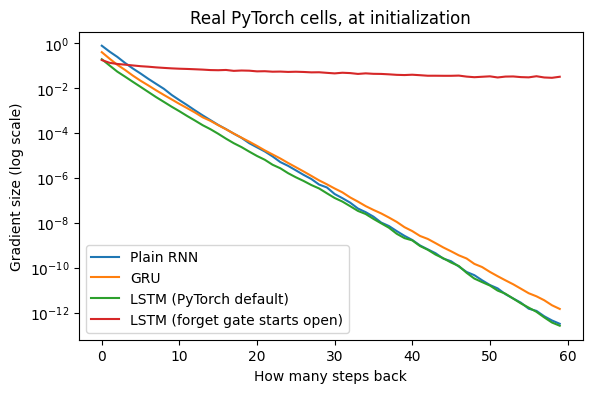

Plain RNN                        10 steps back: 2.9e-03   59 steps back: 3.3e-13
GRU                              10 steps back: 2.0e-03   59 steps back: 1.5e-12
LSTM (PyTorch default)           10 steps back: 9.3e-04   59 steps back: 2.7e-13
LSTM (forget gate starts open)   10 steps back: 7.3e-02   59 steps back: 3.2e-02


In [ ]:
def open_forget_gate(lstm, bias=2.0):
    """Start the LSTM's forget gate mostly open. PyTorch's gate order is (input, forget, candidate, output)."""
    h = lstm.hidden_size
    with torch.no_grad():
        lstm.bias_ih_l0[h:2 * h] = bias
        lstm.bias_hh_l0[h:2 * h] = 0

def gradient_profile(cell, T=60, hid=32, n_init=5, open_gate=False):
    """Average size of d h_T / d x_t at initialization, for every t, over several random initializations."""
    sizes = np.zeros(T)
    for seed in range(n_init):
        torch.manual_seed(seed)
        rnn = {'rnn': nn.RNN, 'gru': nn.GRU, 'lstm': nn.LSTM}[cell](2, hid, batch_first=True)
        if open_gate:
            open_forget_gate(rnn)
        x = torch.randn(1, T, 2)
        jac = torch.autograd.functional.jacobian(lambda z: rnn(z)[0][0, -1], x)    # (hid, 1, T, 2)
        sizes += jac.squeeze(1).norm(dim=(0, 2)).numpy()
    return (sizes / n_init)[::-1]                                                   # index = how many steps back

profiles = {
    'Plain RNN': gradient_profile('rnn'),
    'GRU': gradient_profile('gru'),
    'LSTM (PyTorch default)': gradient_profile('lstm'),
    'LSTM (forget gate starts open)': gradient_profile('lstm', open_gate=True),
}

plt.figure(figsize=(6.5, 4))
for name, prof in profiles.items():
    plt.semilogy(prof, label=name)
plt.xlabel('How many steps back')
plt.ylabel('Gradient size (log scale)')
plt.title('Real PyTorch cells, at initialization')
plt.legend()
plt.show()
for name, prof in profiles.items():
    print(f"{name:32s} 10 steps back: {prof[10]:.1e}   59 steps back: {prof[59]:.1e}")

At initialization, the plain RNN's gradient 59 steps back is around $10^{-12}$, as the earlier plot predicted. The GRU and the default LSTM are no better. Gating does not make the gradient survive on its own, but it does make it possible. 

The LSTM's cell-state path is multiplied by $f_t$ at every step, and PyTorch starts the forget-gate bias at 0, so $f_t \approx 0.5$ and that path halves each step. Start the gate open and the same architecture keeps a gradient of about $3 \times 10^{-2}$ at 59 steps, roughly ten orders of magnitude more. Training moves the gates, so this is where learning starts, not where it ends. But a learning signal that starts at $10^{-12}$ has a hard time getting going.

Second, a task that genuinely needs a long memory. A robot lines up at a station, and for its first 5 steps it drives along the heading it will leave on, then it idles with jitter, then it leaves along that heading. The idle wobble says nothing about the heading, so the only information about where it will go sits at the very start of the history. We sweep the history length from 20 to 200 steps and train each cell with identical settings on several random seeds. Ignoring the cue entirely gives an ADE of about 2.0. Each dot below is one training run, colored by where it ended up.

This sweep trains about 175 models, so it ran offline and the per-seed results are stored in the cell below. Set `RERUN = True` to regenerate them (about 40 minutes). The 200-step column has 4 seeds per cell and the others have 8.

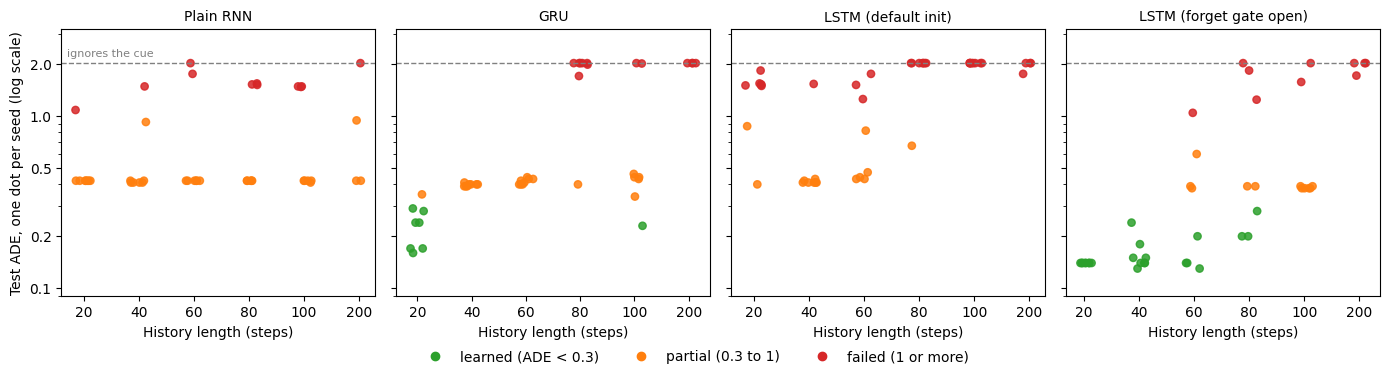

Runs per tier at each history length:  learned (ADE < 0.3) / partial (0.3 to 1) / failed (>= 1)
                                 20       40       60       80      100      200
Plain RNN                     0/7/1    0/7/1    0/6/2    0/5/3    0/5/3    0/3/1
GRU                           7/1/0    0/8/0    0/8/0    0/1/7    1/5/2    0/0/4
LSTM (default init)           0/2/6    0/7/1    0/5/3    0/1/7    0/0/8    0/0/4
LSTM (forget gate open)       8/0/0    8/0/0    4/3/1    3/2/3    0/6/2    0/0/4


In [ ]:
RERUN = False    # True retrains every stored experiment from here on (roughly 40 minutes); False loads the saved results

CUE_STEPS = 5       # the first steps show the heading the robot is about to leave on
HOLD_LAG = 100      # default total observed history; everything after the cue is idling

def make_hold_dataset(n, seed, T=HOLD_LAG):
    """A robot lines up (drives along its departure heading for CUE_STEPS), idles with jitter, then leaves that way."""
    rng = np.random.default_rng(seed)
    theta, speed = rng.uniform(0, 2 * np.pi, n), rng.uniform(0.15, 0.3, n)
    heading = np.stack([np.cos(theta), np.sin(theta)], 1)
    hist, pos = np.zeros((n, T, 2)), np.zeros((n, 2))
    for t in range(CUE_STEPS):
        hist[:, t] = pos
        pos = pos + heading * speed[:, None]
    hold, jitter = pos.copy(), np.zeros((n, 2))
    for t in range(CUE_STEPS, T):
        jitter = 0.8 * jitter + rng.normal(0, 0.04, (n, 2))      # mean-reverting wobble that says nothing about the heading
        hist[:, t] = hold + jitter
    leave = np.stack([heading * speed[:, None] * 2 * (k + 1) for k in range(M)], 1)     # departs at twice the cue speed
    future = (hold[:, None, :] + leave - hist[:, -1:, :]).reshape(n, -1)
    obs = hist + rng.normal(0, NOISE, hist.shape)
    obs = obs - obs[:, -1:, :]                                    # relative to the latest observation, as everywhere else
    as_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return as_t(obs), as_t(future)

class HoldPredictor(nn.Module):
    """History of (x, y) -> recurrent encoder -> final hidden state -> Regression Head, for any history length."""
    def __init__(self, cell, hidden=64):
        super().__init__()
        self.rnn = {'rnn': nn.RNN, 'gru': nn.GRU, 'lstm': nn.LSTM}[cell](2, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, 64), nn.ReLU(), nn.Linear(64, 2 * M))
    def forward(self, x):
        states, _ = self.rnn(x)
        return self.head(states[:, -1])

def fit_hold(model, X, Y, epochs=30, lr=3e-3, seed=0):
    """Same recipe as fit() above, for plain (history, future) tensors."""
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    for _ in range(epochs):
        order = torch.randperm(len(X))
        for i in range(0, len(X), 128):
            idx = order[i:i + 128]
            loss = ((model(X[idx]) - Y[idx]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
    return model.eval()

def ade_of(model, X, Y):
    with torch.no_grad():
        return (model(X) - Y).reshape(-1, M, 2).norm(dim=2).mean().item()

def train_and_score(build, train_data, test_data, seed):
    torch.manual_seed(seed)                      # same seed for the initialization and for the training order
    return ade_of(fit_hold(build(), *train_data, seed=seed), *test_data)

def build_lstm_open():
    model = HoldPredictor('lstm')
    open_forget_gate(model.rnn)
    return model

HOLD_BUILDERS = {'Plain RNN': lambda: HoldPredictor('rnn'),
                 'GRU': lambda: HoldPredictor('gru'),
                 'LSTM (default init)': lambda: HoldPredictor('lstm'),
                 'LSTM (forget gate open)': build_lstm_open}
HOLD_LAGS = [20, 40, 60, 80, 100]

def run_hold_sweep(lags, n_seeds):
    results = {name: {} for name in HOLD_BUILDERS}
    for lag in lags:
        X_tr, Y_tr = make_hold_dataset(4000, seed=1, T=lag)
        X_te, Y_te = make_hold_dataset(1000, seed=2, T=lag)
        for name, build in HOLD_BUILDERS.items():
            results[name][lag] = [round(train_and_score(build, (X_tr, Y_tr), (X_te, Y_te), s), 2) for s in range(n_seeds)]
    return results

# per-seed ADE for every cell, 8 seeds per lag (200 steps: 4 seeds). Produced by run_hold_sweep(); see RERUN above
STORED_HOLD = {
    'Plain RNN': {
        20: [0.42, 0.42, 0.42, 1.08, 0.42, 0.42, 0.42, 0.42],
        40: [0.41, 0.92, 0.42, 0.42, 1.48, 0.41, 0.41, 0.41],
        60: [0.42, 0.42, 2.02, 1.75, 0.42, 0.42, 0.42, 0.42],
        80: [0.42, 0.42, 1.51, 1.54, 1.52, 0.42, 0.42, 0.42],
        100: [1.48, 0.42, 0.42, 1.47, 0.42, 0.41, 0.42, 1.48],
        200: [2.02, 0.42, 0.42, 0.94],
    },
    'GRU': {
        20: [0.24, 0.28, 0.29, 0.24, 0.17, 0.17, 0.35, 0.16],
        40: [0.4, 0.41, 0.4, 0.39, 0.4, 0.4, 0.39, 0.39],
        60: [0.41, 0.4, 0.4, 0.44, 0.4, 0.43, 0.42, 0.43],
        80: [0.4, 2.02, 2.02, 2.02, 2.02, 1.98, 2.02, 1.7],
        100: [2.02, 0.23, 2.01, 0.46, 0.43, 0.44, 0.34, 0.44],
        200: [2.02, 2.02, 2.02, 2.02],
    },
    'LSTM (default init)': {
        20: [0.87, 0.4, 1.83, 1.52, 1.5, 1.54, 1.49, 1.51],
        40: [0.41, 0.41, 0.43, 0.41, 0.41, 0.42, 1.53, 0.41],
        60: [0.44, 0.43, 1.25, 1.75, 0.43, 0.47, 0.82, 1.51],
        80: [2.02, 2.02, 2.02, 2.02, 2.02, 0.67, 2.02, 2.02],
        100: [2.02, 2.02, 2.02, 2.02, 2.02, 2.02, 2.02, 2.02],
        200: [1.75, 2.02, 2.02, 2.02],
    },
    'LSTM (forget gate open)': {
        20: [0.14, 0.14, 0.14, 0.14, 0.14, 0.14, 0.14, 0.14],
        40: [0.18, 0.14, 0.14, 0.15, 0.13, 0.15, 0.24, 0.14],
        60: [1.04, 0.13, 0.14, 0.38, 0.14, 0.6, 0.39, 0.2],
        80: [1.24, 2.02, 0.39, 0.2, 0.39, 0.2, 1.83, 0.28],
        100: [0.38, 1.57, 0.39, 0.38, 2.02, 0.38, 0.38, 0.39],
        200: [1.71, 2.02, 2.02, 2.02],
    },
}
hold_sweep = run_hold_sweep(HOLD_LAGS, n_seeds=8) if RERUN else STORED_HOLD

# ADE of "stay put", which is what a model that ignores the cue is stuck with
no_memory = make_hold_dataset(1000, seed=2, T=20)[1].reshape(-1, M, 2).norm(dim=2).mean().item()

from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter, ScalarFormatter

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
rng_plot = np.random.default_rng(0)
tier_color = lambda e: 'tab:green' if e < 0.3 else ('tab:orange' if e < 1.0 else 'tab:red')
for ax, (name, by_lag) in zip(axes, hold_sweep.items()):
    for j, (lag, errs) in enumerate(by_lag.items()):
        ax.scatter(j + rng_plot.uniform(-0.15, 0.15, len(errs)), errs, c=[tier_color(e) for e in errs], s=28, alpha=0.85)
    ax.axhline(no_memory, color='gray', ls='--', lw=1)
    ax.set_yscale('log'); ax.set_ylim(0.09, 3.2)
    ax.set_yticks([0.1, 0.2, 0.5, 1, 2]); ax.yaxis.set_major_formatter(ScalarFormatter()); ax.yaxis.set_minor_formatter(NullFormatter())
    ax.set_xticks(range(len(by_lag))); ax.set_xticklabels(list(by_lag)); ax.set_title(name, fontsize=10)
    ax.set_xlabel('History length (steps)')
axes[0].set_ylabel('Test ADE, one dot per seed (log scale)')
axes[0].text(-0.3, no_memory * 1.1, 'ignores the cue', color='gray', fontsize=8)
fig.legend(handles=[Line2D([], [], marker='o', ls='', color=c, label=l) for c, l in
                    [('tab:green', 'learned (ADE < 0.3)'), ('tab:orange', 'partial (0.3 to 1)'), ('tab:red', 'failed (1 or more)')]],
           loc='lower center', ncol=3, frameon=False, bbox_to_anchor=(0.5, -0.06))
plt.tight_layout()
plt.show()

print("Runs per tier at each history length:  learned (ADE < 0.3) / partial (0.3 to 1) / failed (>= 1)")
print(f"{'':26s}" + ''.join(f'{lag:>9d}' for lag in hold_sweep['Plain RNN']))
for name, by_lag in hold_sweep.items():
    cells_ = [f"{sum(e < 0.3 for e in v)}/{sum(0.3 <= e < 1.0 for e in v)}/{sum(e >= 1.0 for e in v)}" for v in by_lag.values()]
    print(f"{name:26s}" + ''.join(f'{c:>9s}' for c in cells_))

This is a messy result. Each run ends in one of three places: *learned* (ADE under about 0.3), *partial* (a plateau near 0.4, where the model uses some of the cue but not all of it), or *failed* (about 2.0 or worse, the cue ignored).

The open-gate LSTM is the only recurrent cell that reliably learns the cue fully, and it only does so at the short lags. All 16 runs at 20 and 40 steps reach an ADE of about 0.14. Then full successes fade: 4 of 8 at 60 steps, 3 of 8 at 80, none at 100, and at 200 steps all four runs fail.

The default LSTM is the worst of the four; it fails in 6 of 8 runs at only 20 steps, and in all 8 at 100. It is the same architecture as the open-gate LSTM, and the only difference is where the forget gate starts. The name "LSTM" buys nothing by itself. A forget-gate bias of about 1 to 2 is a standard recommendation (Jozefowicz et al., 2015) for exactly this reason.

The plain RNN is never a clean success or a clean failure. It sits on the partial plateau in 5 to 7 of 8 runs at every length and never reaches the learned tier in any of its 44 runs. This is what a vanishing gradient looks like in practice. It is rarely a flat zero, more often an optimizer that gets only part of the way, and unreliably.

The GRU lands in between; it mostly learns at 20 steps, plateaus at 40 and 60, and then fails in 7 of 8 runs at 80, with a messy recovery at 100. We didn't investigate that dip, so treat the middle of this row as noise around a downward trend.

The pattern to trust is that gating helps only when it starts open, and only up to a point. By 100 to 200 steps, every recurrent cell here is out of its depth.

### A Field-Shaped Version: The Scoring Cycle

The robot-at-a-station task is deliberately stark. Here is a version shaped more like a match. An opponent cycles between an intake zone (at the origin) and a scoring spot that it keeps for the whole match. 

We observe 80 steps (8 seconds at 10 Hz). It dwells at the scoring spot, drives back to the intake, dwells again, and then starts a decoy leg out of the intake in a random direction, like weaving around a field element. The next 8 steps curve back toward the scoring spot.

The decoy heading says nothing about where the robot is going. The only clue is where it was about 70 steps ago, the last time it scored. A model that only sees the last few steps can't know the answer; one that carries the previous cycle's location can. We add a full-history MLP (which sees all 80 steps at once) as an upper bound on how much the history can tell us. Results are stored for the same reason as above (`RERUN`), and this one is only 3 seeds.

In [ ]:
CYCLE_T = 80     # observed steps: 10 at the scoring spot, 50 driving back, 10 at the intake, 10 on the decoy leg

def make_cycle_dataset(n, seed):
    """One scoring cycle. The scoring spot S is fixed for the match. We watch the robot dwell at S, drive back to the
    intake (the origin), dwell, and start a decoy leg in a random direction. The next steps curve toward S."""
    rng = np.random.default_rng(seed)
    r, a = rng.uniform(3, 5, n), rng.uniform(0, 2 * np.pi, n)
    spot = np.stack([r * np.cos(a), r * np.sin(a)], 1)
    phi, v = rng.uniform(0, 2 * np.pi, n), rng.uniform(2.0, 3.0, n)
    decoy = np.stack([np.cos(phi), np.sin(phi)], 1) * v[:, None]
    P, jitter, vel = np.zeros((n, CYCLE_T + M, 2)), np.zeros((n, 2)), None
    for t in range(CYCLE_T + M):
        if t < 80:
            if t < 10:    p = spot                                                  # dwelling at the scoring spot
            elif t < 60:  s = (t - 10) / 50; p = spot * (1 - s * s * (3 - 2 * s))   # smooth drive back to the intake
            elif t < 70:  p = np.zeros((n, 2))                                      # dwelling at the intake
            else:         p = decoy * 0.1 * (t - 69)                                # decoy leg: heading says nothing about S
            jitter = 0.8 * jitter + rng.normal(0, 0.03, (n, 2))
            P[:, t] = p + (jitter if (t < 10 or 60 <= t < 70) else 0)
        else:
            if t == 80: vel = decoy.copy()
            if t >= 82:                                                             # now turn toward the scoring spot
                d = spot - P[:, t - 1]
                vel = vel + (v[:, None] * d / np.linalg.norm(d, axis=1, keepdims=True) - vel) / 3.0
            P[:, t] = P[:, t - 1] + vel * 0.1
    obs = P[:, :CYCLE_T] + rng.normal(0, NOISE, (n, CYCLE_T, 2))
    future = (P[:, CYCLE_T:] - P[:, CYCLE_T - 1:CYCLE_T]).reshape(n, -1)
    as_t = lambda a: torch.tensor(a, dtype=torch.float32)
    return as_t(obs - obs[:, -1:, :]), as_t(future)

class CycleWindow(nn.Module):
    """Feedforward net on the last K steps only (06's model)."""
    def __init__(self, K=5):
        super().__init__()
        self.K = K
        self.net = nn.Sequential(nn.Linear(2 * K, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 2 * M))
    def forward(self, x):
        return self.net(x[:, -self.K:].reshape(len(x), -1))

class CycleFullHistory(nn.Module):
    """Feedforward net that sees all 80 steps at once: an upper bound on what the history can tell us."""
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(2 * CYCLE_T, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 2 * M))
    def forward(self, x):
        return self.net(x.reshape(len(x), -1))

CYCLE_BUILDERS = {'Window MLP (last 5 steps)': lambda: CycleWindow(),
                  'Full-history MLP': lambda: CycleFullHistory(),
                  'Plain RNN': lambda: HoldPredictor('rnn'),
                  'LSTM (default init)': lambda: HoldPredictor('lstm'),
                  'LSTM (forget gate open)': build_lstm_open}

def run_cycle(builders, n_seeds=3):
    X_tr, Y_tr = make_cycle_dataset(4000, seed=1)
    X_te, Y_te = make_cycle_dataset(1000, seed=2)
    out = {}
    for name, build in builders.items():
        out[name] = [round(train_and_score(build, (X_tr, Y_tr), (X_te, Y_te), s), 3) for s in range(n_seeds)]
    return out

# per-seed ADE (3 seeds), produced by run_cycle(); see RERUN above
STORED_CYCLE = {
    'Window MLP (last 5 steps)': [0.334, 0.334, 0.334],
    'Full-history MLP': [0.025, 0.024, 0.025],
    'Plain RNN': [0.337, 0.336, 0.335],
    'LSTM (default init)': [0.226, 0.205, 0.159],
    'LSTM (forget gate open)': [0.025, 0.026, 0.024],
}
cycle_results = run_cycle(CYCLE_BUILDERS) if RERUN else STORED_CYCLE

X_te_c, Y_te_c = make_cycle_dataset(1000, seed=2)
cv_pred = ((X_te_c[:, -1] - X_te_c[:, -2])[:, None, :] * torch.arange(1, M + 1).float()[None, :, None]).reshape(1000, -1)
print(f"Constant velocity: ADE = {(cv_pred - Y_te_c).reshape(-1, M, 2).norm(dim=2).mean():.3f}")
print(f"Staying put:       ADE = {Y_te_c.reshape(-1, M, 2).norm(dim=2).mean():.3f}\n")
for name, errs in cycle_results.items():
    print(f"{name:26s} ADE per seed: {'  '.join(f'{e:.3f}' for e in errs)}")

Constant velocity: ADE = 0.715
Staying put:       ADE = 0.648

Window MLP (last 5 steps)  ADE per seed: 0.334  0.334  0.334
Full-history MLP           ADE per seed: 0.025  0.024  0.025
Plain RNN                  ADE per seed: 0.337  0.336  0.335
LSTM (default init)        ADE per seed: 0.226  0.205  0.159
LSTM (forget gate open)    ADE per seed: 0.025  0.026  0.024


The window MLP and the plain RNN land at the same ADE (about 0.335), so the RNN used nothing from the previous cycle. The full-history MLP reaches 0.025, which shows the information really is in the history. The default LSTM gets part of the way (0.16 to 0.23, quite seed-dependent), and the open-gate LSTM matches the full-history upper bound at 0.025.

That's the same pattern as the robot-at-a-station task, on something closer to real opponent behavior. Two notes on reading it. With 3 seeds, don't read anything into small differences, but 0.335 vs. 0.025 is not subtle. And here the open-gate LSTM works well at 70 steps, while in the previous experiment its full successes had faded by 80 to 100 steps, so how far gating reaches depends on the task as well as the lag. The practical lesson: a recurrent model that silently ignores its early history can look fine on average, so always check it against a no-memory baseline.

### Reading Any Length of History

So far, recurrence has only paid off when we handed it a long memory task. The other property it's supposed to buy is *variable-length* histories, so let's test that too. A real tracker's tracks have all different ages. A robot that just entered the camera's view has 3 observations, not 12. We'll train an LSTM and a window-MLP on histories whose length is randomly cut to between 3 and 12 steps, then test both at each fixed length.

The MLP has a fixed input size, so for a short history we zero out the missing steps and also hand it a mask saying which steps are real (the fairest version of a fixed-size model we can construct). The LSTM instead gets only the real steps: PyTorch's `pack_padded_sequence` tells it where each sequence actually ends.

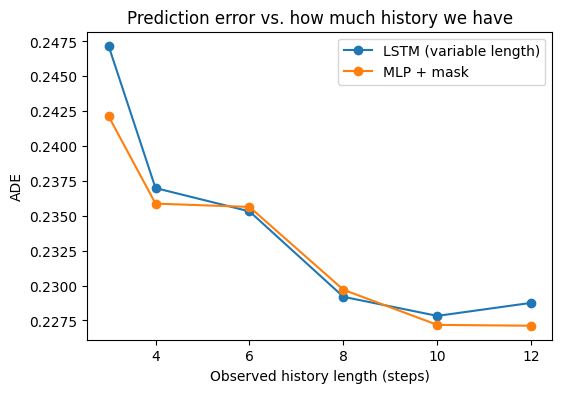

  history length       3       4       6       8      10      12
LSTM (variable length)   0.247   0.237   0.235   0.229   0.228   0.229
      MLP + mask   0.242   0.236   0.236   0.230   0.227   0.227
Parameters: LSTM = 22,608, MLP = 14,032


In [9]:
def truncate_history(opp, L):
    """Keep only the last L steps of each history. Returns the (zeroed) history and a 0/1 validity mask."""
    valid = (torch.arange(T_HIST)[None, :] >= (T_HIST - L)[:, None]).float()
    return opp * valid[..., None], valid

def shift_valid_to_front(x, L):
    """Right-aligned valid steps -> left-aligned, which is what pack_padded_sequence expects."""
    idx = (torch.arange(T_HIST)[None, :] + (T_HIST - L)[:, None]).clamp(max=T_HIST - 1)
    return torch.gather(x, 1, idx[..., None].expand_as(x))

class VarLengthLSTM(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.rnn = nn.LSTM(2, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden, 64), nn.ReLU(), nn.Linear(64, 2 * M))
    def forward(self, opp, L):
        opp, _ = truncate_history(opp, L)
        packed = pack_padded_sequence(shift_valid_to_front(opp, L), L, batch_first=True, enforce_sorted=False)
        _, (h_n, _) = self.rnn(packed)         # h_n is the hidden state at each sequence's own last real step
        return self.head(h_n[-1])

class VarLengthMLP(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(T_HIST * 3, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 2 * M))
    def forward(self, opp, L):
        opp, valid = truncate_history(opp, L)
        return self.net(torch.cat([opp.reshape(len(opp), -1), valid], dim=1))

def fit_var_length(model, epochs=40, lr=3e-3, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, epochs)
    n = len(train['opp'])
    for _ in range(epochs):
        order = torch.randperm(n)
        for i in range(0, n, 128):
            idx = order[i:i + 128]
            L = torch.randint(3, T_HIST + 1, (len(idx),))        # each example gets its own random history length
            loss = ((model(train['opp'][idx], L) - train['future'][idx]) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        sched.step()
    return model.eval()

var_lstm = fit_var_length(VarLengthLSTM())
var_mlp = fit_var_length(VarLengthMLP())

lengths = [3, 4, 6, 8, 10, 12]
curves = {'LSTM (variable length)': [], 'MLP + mask': []}
with torch.no_grad():
    for L in lengths:
        L_all = torch.full((len(test['opp']),), L)
        curves['LSTM (variable length)'].append(displacement_errors(var_lstm(test['opp'], L_all), test['future']).mean().item())
        curves['MLP + mask'].append(displacement_errors(var_mlp(test['opp'], L_all), test['future']).mean().item())

plt.figure(figsize=(6, 4))
for name, c in curves.items():
    plt.plot(lengths, c, marker='o', label=name)
plt.xlabel('Observed history length (steps)')
plt.ylabel('ADE')
plt.title('Prediction error vs. how much history we have')
plt.legend()
plt.show()
print(f"{'history length':>16}" + ''.join(f"{L:>8}" for L in lengths))
for name, c in curves.items():
    print(f"{name:>16}" + ''.join(f"{v:8.3f}" for v in c))
print(f"Parameters: LSTM = {n_params(var_lstm):,}, MLP = {n_params(var_mlp):,}")

Both models degrade gracefully as the history gets shorter, from an ADE of about 0.23 with a full 12 steps to about 0.245 with just 3, and the two are within 0.005 of each other at every length. So the recurrent network does read any length of history, and one set of weights handles a brand-new track and a mature one. But the MLP-with-a-mask does just as well here, because our histories are tiny.

The difference shows up in how each scales. The LSTM's parameter count is the same whether the history is 12 steps or 1,200, while the MLP's first layer grows with every step it has to accept (it has 3 inputs per step), and it can't read past `T_HIST` at all. At this toy scale the LSTM actually has *more* parameters (22,608 vs. 14,032), so we're not claiming it's cheaper here, only that it doesn't have a hard length limit.

## Interaction: Social Pooling

### What Own-History Models Can't See

Back to the real gap. Let's take a test scene where a defender comes close, and ask the best own-history model we have what it predicts. We'll pick the close-call scene where that model does *worst*: not a typical case, but a clear one. The table at the end gives us a summary. 

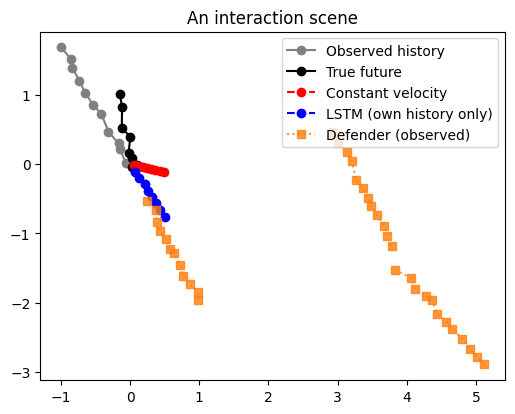

In [10]:
# pick the close-call scene (defender within 0.6) where the own-history LSTM does its worst, a
# rule that doesn't peek at the social model we haven't built yet
with torch.no_grad():
    lstm_err = displacement_errors(models['lstm'](test['opp'], test['nbr'], test['mask']), test['future'])[:, -1]
lstm_err[test['gap'] >= 0.6] = -1
near_idx = lstm_err.argmax().item()
sample = {k: v[near_idx:near_idx + 1] for k, v in test.items()}
with torch.no_grad():
    cv_pred = constant_velocity(sample['opp']).reshape(M, 2).numpy()
    lstm_pred = models['lstm'](sample['opp'], sample['nbr'], sample['mask']).reshape(M, 2).numpy()

true_future = sample['future'].reshape(M, 2).numpy()
hist = sample['opp'][0].numpy()

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(hist[:, 0], hist[:, 1], 'o-', color='gray', label='Observed history')
ax.plot(true_future[:, 0], true_future[:, 1], 'o-', color='black', label='True future')
ax.plot(cv_pred[:, 0], cv_pred[:, 1], 'o--', color='red', label='Constant velocity')
ax.plot(lstm_pred[:, 0], lstm_pred[:, 1], 'o--', color='blue', label='LSTM (own history only)')
d = sample['nbr'][0][:, :, :].numpy()
for k in range(MAX_N):
    if sample['mask'][0, -1, k] > 0:
        ax.plot(d[:, k, 0], d[:, k, 1], 's:', color='tab:orange', alpha=0.8, label='Defender (observed)' if k == 0 else None)
ax.set_aspect('equal'); ax.legend(); ax.set_title('An interaction scene')
plt.show()

Both predictions keep heading the way the history was already going, because that's all the opponent's own history suggests. The true path bends sharply back. The model doesn't "know" there's a defender in the way. Now we give it eyes.

### Pooling Over Neighbors

How do we feed in "the other robots"? The scene has a *variable number* of defenders (0 to 3 here, and in a real match, whoever happens to be nearby), and they have no natural order. A naive approach would give each defender a fixed slot in the input vector, but slot 1 is just whichever defender we happened to list first, so the network would have to relearn the same physics separately for every slot, and it'd treat swapping two defenders as a different situation.

**Social pooling**, the central idea of Social LSTM (Alahi et al., 2016), solves this. At each time step:

1. Run a small shared network over *every* neighbor individually, turning each neighbor's position **relative to the opponent** into an embedding. Same weights for every neighbor.
2. **Pool** those embeddings into one fixed-size vector with an order-independent operation (here, an elementwise max). Zero neighbors, one, or ten all give the same vector size, and shuffling the neighbors doesn't change the result.
3. Concatenate that pooled "who's around me" vector onto the opponent's own position, and feed the result to the recurrent encoder at that step.

The original Social LSTM pools neighbors' *hidden states* over a spatial grid. We're using the simpler, now-more-common version that embeds relative positions and max-pools, which keeps the same two key properties: variable neighbor count and no ordering.

Position *relative to the opponent* matters here, for the same reason 06 made everything relative to the last position: what a defender does to the opponent depends on where the defender is *relative to them*, not on absolute field coordinates.

In [11]:
class SocialLSTM(nn.Module):
    """Opponent history + pooled neighbor embeddings at every step -> LSTM -> Regression Head."""
    def __init__(self, hidden=64, nbr_dim=32, attention=False):
        super().__init__()
        self.attention = attention
        self.hidden = hidden
        self.nbr_net = nn.Sequential(nn.Linear(2, nbr_dim), nn.ReLU(), nn.Linear(nbr_dim, nbr_dim), nn.ReLU())
        self.rnn = nn.LSTM(2 + nbr_dim, hidden, batch_first=True)
        self.head = nn.Sequential(nn.Linear(hidden * (2 if attention else 1), 64), nn.ReLU(), nn.Linear(64, 2 * M))

    def forward(self, opp, nbr, mask):
        rel = (nbr - opp[:, :, None, :]) * mask[..., None]        # each neighbor relative to the opponent at that step
        emb = self.nbr_net(rel) * mask[..., None]                  # shared embedding network; padded slots zeroed
        pooled = emb.max(dim=2).values                             # order-independent pooling over neighbors
        states, _ = self.rnn(torch.cat([opp, pooled], dim=-1))
        last = states[:, -1]
        if self.attention:
            scores = (states * last[:, None, :]).sum(-1) / self.hidden ** 0.5   # how relevant is each past step to "now"?
            weights = torch.softmax(scores, dim=1)
            context = (weights[..., None] * states).sum(1)
            last = torch.cat([last, context], dim=-1)
        return self.head(last)

social_lstm = fit(SocialLSTM())
with torch.no_grad():
    results['Social LSTM'] = evaluate(social_lstm(test['opp'], test['nbr'], test['mask']))

# the two properties pooling is supposed to give us
with torch.no_grad():
    base = social_lstm(test['opp'], test['nbr'], test['mask'])
    perm = torch.tensor([2, 0, 1])
    shuffled = social_lstm(test['opp'], test['nbr'][:, :, perm], test['mask'][:, :, perm])
    print(f"Shuffling the order of the defenders changes predictions by at most {(base - shuffled).abs().max():.1e}")
    more_slots = torch.cat([test['nbr'], torch.zeros(len(test['opp']), T_HIST, 4, 2)], dim=2)
    more_mask = torch.cat([test['mask'], torch.zeros(len(test['opp']), T_HIST, 4)], dim=2)
    print(f"Handing it 4 extra empty slots changes predictions by at most {(base - social_lstm(test['opp'], more_slots, more_mask)).abs().max():.1e}")

Shuffling the order of the defenders changes predictions by at most 0.0e+00
Handing it 4 extra empty slots changes predictions by at most 0.0e+00


Both checks come out at floating-point zero: the model genuinely doesn't care how the neighbors are ordered, or how many empty slots surround them. For contrast, here's the "obvious" alternative: a model that gets the neighbors in fixed slots, the way 06's model got its window of positions, with no pooling and no recurrence.

In [12]:
class SlotMLP(nn.Module):
    """Flatten the opponent history and every neighbor slot into one big vector (no pooling, no recurrence)."""
    def __init__(self):
        super().__init__()
        in_dim = T_HIST * 2 + T_HIST * MAX_N * 2 + T_HIST * MAX_N
        self.net = nn.Sequential(nn.Linear(in_dim, 128), nn.ReLU(), nn.Linear(128, 64), nn.ReLU(), nn.Linear(64, 2 * M))
    def forward(self, opp, nbr, mask):
        rel = (nbr - opp[:, :, None, :]) * mask[..., None]
        return self.net(torch.cat([opp.reshape(len(opp), -1), rel.reshape(len(opp), -1), mask.reshape(len(opp), -1)], dim=1))

slot_mlp = fit(SlotMLP())
with torch.no_grad():
    results['Slot MLP (fixed slots)'] = evaluate(slot_mlp(test['opp'], test['nbr'], test['mask']))
    slot_shuffled = slot_mlp(test['opp'], test['nbr'][:, :, perm], test['mask'][:, :, perm])
    print(f"Shuffling the defenders changes the slot-MLP's predictions by up to {(slot_mlp(test['opp'], test['nbr'], test['mask']) - slot_shuffled).abs().max():.2f}")

for name, r in results.items():
    print(f"{name:24s} ADE={r['ade']:.3f}  FDE={r['fde']:.3f}   ADE when interacting={r['ade_near']:.3f}, not={r['ade_far']:.3f}")

Shuffling the defenders changes the slot-MLP's predictions by up to 1.07
Constant velocity        ADE=0.329  FDE=0.602   ADE when interacting=0.405, not=0.291
Window MLP (K=5)         ADE=0.235  FDE=0.447   ADE when interacting=0.347, not=0.178
RNN (own history)        ADE=0.223  FDE=0.431   ADE when interacting=0.318, not=0.175
GRU (own history)        ADE=0.222  FDE=0.429   ADE when interacting=0.316, not=0.174
LSTM (own history)       ADE=0.225  FDE=0.432   ADE when interacting=0.319, not=0.177
Social LSTM              ADE=0.154  FDE=0.278   ADE when interacting=0.184, not=0.139
Slot MLP (fixed slots)   ADE=0.209  FDE=0.392   ADE when interacting=0.292, not=0.168


This is the biggest change in the notebook. The Social LSTM cuts overall ADE from about 0.225 (own-history LSTM) to 0.154, and FDE from 0.43 to 0.28. The improvement concentrates where it should; in the scenes where a defender comes close, ADE drops from about 0.32 to 0.18. The model has seen the defender approaching *before* the opponent swerves, so it can predict the swerve instead of reacting to it.

The slot-based MLP got some of the benefit (ADE 0.209) but far less, and it's fragile in the way we predicted. Shuffling the defenders' order changes its predictions by a large margin, because as far as it can tell, swapping two defenders is a different situation. 

One caveat on reading this comparison: the slot-MLP and the Social LSTM differ in *both* pooling and recurrence, so it isn't a clean ablation of pooling alone. But we already saw that recurrence on its own was worth little here, so most of the gap is plausibly the pooling.

The overall lesson of the notebook so far: the biggest accuracy gain came from giving the model the*right information (the defenders), not from a fancier way of remembering the opponent's own past.

## Toward Attention

Everything recurrent so far shares one structural limit, which we flagged earlier: the encoder squeezes the entire history into a single vector, the final hidden state, and the prediction head sees nothing else. If a detail from step 2 matters for the prediction, it has to survive 10 updates to that vector first.

The first step toward fixing that is simple. The LSTM already *computes* a hidden state at every step; we just throw all but the last away. What if the prediction head could look back across all of them and choose which ones to weight? 

That is **attention** over the encoder's hidden states, the same dot-product-and-softmax mechanism `genai_architecture_primer/02-attention-mechanism.ipynb` builds from scratch. The last state acts as the **query**, every state acts as a **key** and a **value**, and the softmaxed scores say how much each past step contributes. The `attention=True` option in `SocialLSTM` above does exactly this. Let's see if it helps.

In [13]:
social_attn = fit(SocialLSTM(attention=True))
with torch.no_grad():
    results['Social LSTM + attention'] = evaluate(social_attn(test['opp'], test['nbr'], test['mask']))
    r = results['Social LSTM + attention']
print(f"Social LSTM + attention: ADE={r['ade']:.3f}  FDE={r['fde']:.3f}   ADE when interacting={r['ade_near']:.3f}, not={r['ade_far']:.3f}")

Social LSTM + attention: ADE=0.154  FDE=0.277   ADE when interacting=0.188, not=0.137


Oops, it doesn't. Overall ADE is 0.154 either way, and the differences in the other columns (0.184 vs. 0.188 in interacting scenes) are small enough that a different random seed could flip them, so please don't read anything into them. 

With only 12 steps, the last hidden state already carries everything the prediction needs, so there's nothing for attention to rescue.

Attention earns its keep when the history is long enough that one vector can't hold it, or when the *right* part of the past depends on the situation. It's also the mechanism that would let each agent attend to each other agent, replacing the max-pool, which is the interaction-modeling limit noted below. 

Take the logical extreme of this idea, dropping the recurrence entirely and letting every step attend to every other step, and you have the Transformer. `06c-transformer-trajectory-prediction.ipynb` builds that, using the attention mechanism that `genai_architecture_primer/02` and `03` build from scratch (on text, not trajectories).

The 12-step data couldn't show the benefits of attention, but the long-memory tasks can. We give attention the same two tasks. `StepAttention` below is the attention head from `SocialLSTM`, applied either to an LSTM's per-step states (LSTM + attention) or, with the recurrence removed entirely, to a learned embedding of each step plus its position (attention only). It reuses `fit_hold` and the datasets from above, and its results are stored for the same reason (`RERUN`).

In [ ]:
class StepAttention(nn.Module):
    """History -> per-step states -> attention (last state is the query) -> Regression Head, for any history length.
    With recurrent=True the states come from an LSTM, as in SocialLSTM(attention=True); with False they are
    just a learned embedding of each (x, y) plus a learned position, so there is no recurrence at all."""
    def __init__(self, length, recurrent, d=64):
        super().__init__()
        self.recurrent, self.d = recurrent, d
        if recurrent:
            self.encoder = nn.LSTM(2, d, batch_first=True)
        else:
            self.embed, self.pos = nn.Linear(2, d), nn.Parameter(torch.randn(length, d) * 0.1)
        self.q, self.k, self.v = nn.Linear(d, d), nn.Linear(d, d), nn.Linear(d, d)
        self.head = nn.Sequential(nn.Linear(2 * d, 64), nn.ReLU(), nn.Linear(64, 2 * M))
    def forward(self, x):
        states = self.encoder(x)[0] if self.recurrent else self.embed(x) + self.pos
        last = states[:, -1]
        scores = (self.k(states) * self.q(last)[:, None, :]).sum(-1) / self.d ** 0.5
        context = (torch.softmax(scores, dim=1)[..., None] * self.v(states)).sum(1)
        return self.head(torch.cat([last, context], dim=-1))

def run_attention(n_seeds=4):
    out = {'LSTM + attention': {}, 'Attention only': {}}
    for lag in [100, 200]:
        X_tr, Y_tr = make_hold_dataset(4000, seed=1, T=lag)
        X_te, Y_te = make_hold_dataset(1000, seed=2, T=lag)
        for name, recurrent in [('LSTM + attention', True), ('Attention only', False)]:
            build = lambda: StepAttention(lag, recurrent)
            out[name][lag] = [round(train_and_score(build, (X_tr, Y_tr), (X_te, Y_te), s), 2) for s in range(n_seeds)]
    return out

# per-seed ADE (4 seeds) on the long-memory task, produced by run_attention(); see RERUN above
STORED_ATTN = {
    'Attention only': {
        100: [0.25, 0.25, 0.29, 0.25],
        200: [0.24, 0.24, 0.24, 0.24],
    },
    'LSTM + attention': {
        100: [0.12, 0.12, 0.14, 0.14],
        200: [0.14, 0.19, 0.24, 0.16],
    },
}
attn_hold = run_attention() if RERUN else STORED_ATTN

print("Long-memory task, ADE per seed (ignoring the cue: about 2.0):")
for lag in [100, 200]:
    for name in ['LSTM (forget gate open)']:
        print(f"  {lag:3d} steps  {name:26s}", '  '.join(f'{e:.2f}' for e in hold_sweep[name][lag]))
    for name, by_lag in attn_hold.items():
        print(f"  {lag:3d} steps  {name:26s}", '  '.join(f'{e:.2f}' for e in by_lag[lag]))

# the scoring-cycle task too: a small fixed-length version of the same comparison
STORED_CYCLE_ATTN = {'LSTM + attention': [0.049, 0.053, 0.045], 'Attention only': [0.331, 0.331, 0.331]}
if RERUN:
    X_tr, Y_tr = make_cycle_dataset(4000, seed=1); X_te, Y_te = make_cycle_dataset(1000, seed=2)
    cycle_attn = {name: [round(train_and_score(lambda: StepAttention(CYCLE_T, rec), (X_tr, Y_tr), (X_te, Y_te), s), 3) for s in range(3)]
                  for name, rec in [('LSTM + attention', True), ('Attention only', False)]}
else:
    cycle_attn = STORED_CYCLE_ATTN
print("\nScoring-cycle task, ADE per seed (open-gate LSTM: 0.025, window MLP: 0.334):")
for name, errs in cycle_attn.items():
    print(f"  {name:26s}", '  '.join(f'{e:.3f}' for e in errs))

Long-memory task, ADE per seed (ignoring the cue: about 2.0):
  100 steps  LSTM (forget gate open)    0.38  1.57  0.39  0.38  2.02  0.38  0.38  0.39
  100 steps  Attention only             0.25  0.25  0.29  0.25
  100 steps  LSTM + attention           0.12  0.12  0.14  0.14
  200 steps  LSTM (forget gate open)    1.71  2.02  2.02  2.02
  200 steps  Attention only             0.24  0.24  0.24  0.24
  200 steps  LSTM + attention           0.14  0.19  0.24  0.16

Scoring-cycle task, ADE per seed (open-gate LSTM: 0.025, window MLP: 0.334):
  LSTM + attention           0.049  0.053  0.045
  Attention only             0.331  0.331  0.331


On the robot-at-a-station task, attention solves what the recurrent cells couldn't. LSTM + attention learned the cue in all 8 runs at 100 and 200 steps (ADE 0.12 to 0.24), and attention only did too (about 0.25). Compare that with the best recurrent result of about 0.38 at 100 steps and total failure at 200. The mechanism is the one from the gradient section; the prediction head has a direct path to the state at every step, so the learning signal for step 3 doesn't have to travel back through 95 squashing updates.

On the scoring-cycle task the picture is mixed. LSTM + attention (0.049) works nearly as well as the open-gate LSTM (0.025), but attention only learned nothing (0.331, the same as the window MLP). We didn't investigate why, so we can't say whether it's the model's size, the position embedding, or optimization. Treat it as a reminder that "attention solves long memory" isn't unconditional, and as a hook for `06c`, which builds the full Transformer.

## Putting It All Together

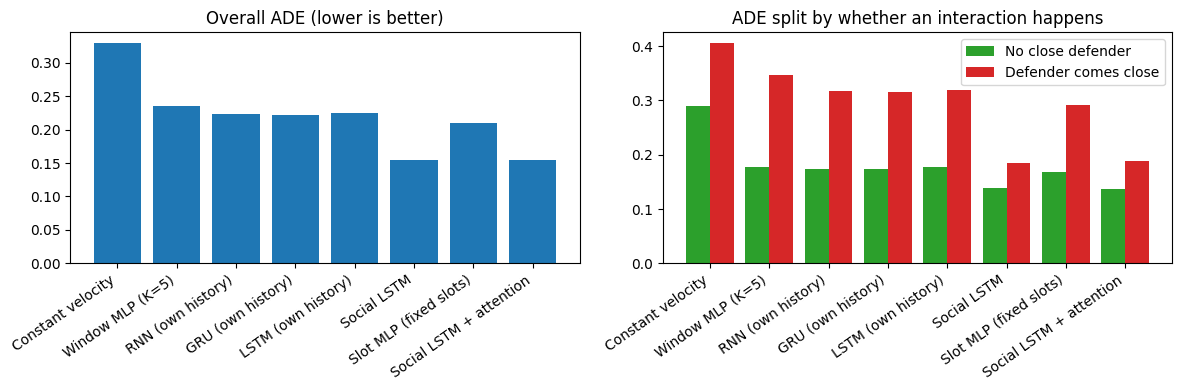

                               ADE     FDE  ADE near   ADE far
Constant velocity            0.329   0.602     0.405     0.291
Window MLP (K=5)             0.235   0.447     0.347     0.178
RNN (own history)            0.223   0.431     0.318     0.175
GRU (own history)            0.222   0.429     0.316     0.174
LSTM (own history)           0.225   0.432     0.319     0.177
Social LSTM                  0.154   0.278     0.184     0.139
Slot MLP (fixed slots)       0.209   0.392     0.292     0.168
Social LSTM + attention      0.154   0.277     0.188     0.137


In [14]:
order = list(results.keys())
x = np.arange(len(order))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].bar(x, [results[k]['ade'] for k in order], color='tab:blue')
axes[0].set_title('Overall ADE (lower is better)')
axes[1].bar(x - 0.2, [results[k]['ade_far'] for k in order], 0.4, label='No close defender', color='tab:green')
axes[1].bar(x + 0.2, [results[k]['ade_near'] for k in order], 0.4, label='Defender comes close', color='tab:red')
axes[1].set_title('ADE split by whether an interaction happens')
axes[1].legend()
for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(order, rotation=35, ha='right')
plt.tight_layout()
plt.show()

print(f"{'':26s} {'ADE':>7} {'FDE':>7} {'ADE near':>9} {'ADE far':>9}")
for k in order:
    r = results[k]
    print(f"{k:26s} {r['ade']:7.3f} {r['fde']:7.3f} {r['ade_near']:9.3f} {r['ade_far']:9.3f}")

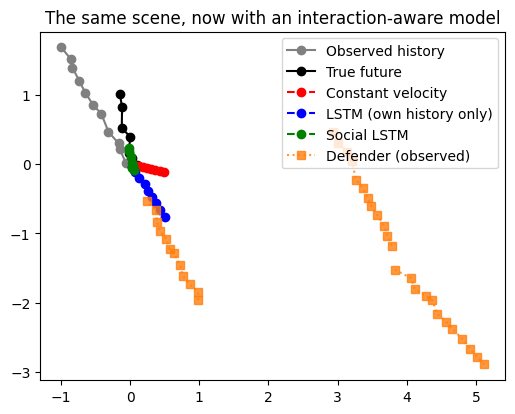

In [15]:
with torch.no_grad():
    social_pred = social_lstm(sample['opp'], sample['nbr'], sample['mask']).reshape(M, 2).numpy()

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot(hist[:, 0], hist[:, 1], 'o-', color='gray', label='Observed history')
ax.plot(true_future[:, 0], true_future[:, 1], 'o-', color='black', label='True future')
ax.plot(cv_pred[:, 0], cv_pred[:, 1], 'o--', color='red', label='Constant velocity')
ax.plot(lstm_pred[:, 0], lstm_pred[:, 1], 'o--', color='blue', label='LSTM (own history only)')
ax.plot(social_pred[:, 0], social_pred[:, 1], 'o--', color='green', label='Social LSTM')
for k in range(MAX_N):
    if sample['mask'][0, -1, k] > 0:
        ax.plot(d[:, k, 0], d[:, k, 1], 's:', color='tab:orange', alpha=0.8, label='Defender (observed)' if k == 0 else None)
ax.set_aspect('equal'); ax.legend(); ax.set_title('The same scene, now with an interaction-aware model')
plt.show()

The picture matches the table. Constant velocity is the worst, the window MLP and the recurrent own-history models are a modest improvement, and the Social LSTM is the clear step change, especially in the red bars (scenes with an interaction). In the single scene above (chosen as the close call where the own-history LSTM does worst, not as a typical case) the Social LSTM is the only prediction that bends back toward where the opponent actually went.

## The Limits of This Approach

Everything we built here is a real, widely used technique, but it's worth being specific about what it still doesn't do.

One hidden state is a bottleneck. On the 12-step data, attention didn't matter. On the long-memory tasks it did, because it learned a cue 100 to 200 steps back in every run where every recurrent cell failed or plateaued. The single-vector bottleneck, plus a gradient that has to travel back through every step, is what attention-based models get around.

Recurrence is also inherently sequential. Step 50 can't be computed until step 49 is done, so training can't parallelize across the sequence. This, along with the long-range decay we plotted, is a big part of why Transformers displaced recurrent models for most sequence work.

Pooling is a coarse model of interaction. A max over neighbor embeddings can say "someone is close on the left," but it has no way for the neighbors to react to each other. Real crowds, and real alliances of robots, do. Models that let every agent attend to every other agent (graph networks, and Transformer-based predictors) handle that, at higher cost.

Every model here outputs a single predicted path, which means it still has the mode-averaging problem from `07`: if the opponent could juke left or right with equal probability, the best single guess is somewhere in between. That's the next notebook's problem.

The opponent here follows a clean repulsion rule. Real robots are driven by humans and strategies we can't write down, and real tracks come from a noisy detector and tracker (`perception_primer/02` and `05`) that drop and swap IDs. A model that looked good on this data would need re-validation on real match film.

Where this leaves the progression: constant velocity (`05`) → fixed window (`06`) → recurrence with social pooling (this notebook) → Transformer over agent-time tokens (`06c`) → multiple hypotheses (`07`). `06c` replaces the recurrent encoder and the pooling with attention, building on the attention mechanism that `genai_architecture_primer/02` and `03` build from scratch (on text, not trajectories).

## Try It Yourself

**1. Does pooling really scale to more defenders?** The model was trained on up to 3 defenders (don't retrain). Build a test set with `make_dataset(500, seed=3, max_n=6)`. Evaluate the trained `social_lstm` on it, and try the `slot_mlp` too. One of them should work with no changes and the other shouldn't be runnable at all. Which is which, and why? Then write one sentence on whether the pooled model's accuracy should be as good as on the 3-defender test set, and what you'd have to change in training to make it so.

**2. How far does gating really go?** Using `make_hold_dataset` and `fit_hold` from the long-memory experiment, try three things. (a) Train all four models on `make_hold_dataset(4000, seed=1, T=200)`. Does the open-gate LSTM still learn the cue? (In our runs, no recurrent cell did.) (b) At `T = 100`, sweep the forget-gate bias over 0, 1, 2, and 4 for the LSTM. Where does it stop helping, and what might a bias that is too large cost? (c) Add gradient clipping (`torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)` right before `opt.step()`) to the plain RNN. Does it help? In one or two sentences, explain why clipping is the right tool for exploding gradients but not for vanishing ones.

In [16]:
# TODO 1: build a max_n=6 test set and evaluate social_lstm on it; then try slot_mlp and note what happens

# TODO 2: train the four models at T=200 and compare how many runs learn the cue

# TODO 3: sweep open_forget_gate(..., bias) over [0, 1, 2, 4] at T = 100

# TODO 4: add clip_grad_norm_ to fit_hold and rerun the plain RNN

## Resources

- Alahi, A. et al. (2016). "Social LSTM: Human Trajectory Prediction in Crowded Spaces." *CVPR 2016*. The paper behind this notebook's social pooling, which pools neighbors' hidden states over a spatial grid (paper).
- Hochreiter, S. & Schmidhuber, J. (1997). "Long Short-Term Memory." *Neural Computation*. The original LSTM paper, which introduced the additive cell state (paper).
- Cho, K. et al. (2014). "Learning Phrase Representations using RNN Encoder-Decoder for Statistical Machine Translation." The paper that introduced the GRU (paper).
- Bahdanau, D., Cho, K. & Bengio, Y. (2015). "Neural Machine Translation by Jointly Learning to Align and Translate." The paper that first added attention on top of a recurrent encoder, the exact step from "Toward Attention" above (paper).
- Salzmann, T. et al. (2020). "Trajectron++: Dynamically-Feasible Trajectory Forecasting With Heterogeneous Data." A real system that models interacting agents with graph-structured recurrent networks, a more expressive version of this notebook's pooling (paper).
- [Colah: Understanding LSTM Networks](https://colah.github.io/posts/2015-08-Understanding-LSTMs/) - the standard visual walkthrough of the LSTM's gates and cell state (blog).
- Pascanu, R., Mikolov, T. & Bengio, Y. (2013). "On the difficulty of training recurrent neural networks." *ICML 2013*. The analysis of vanishing and exploding gradients behind this notebook's gradient section, and the source of gradient clipping (paper).
- Jozefowicz, R., Zaremba, W. & Sutskever, I. (2015). "An Empirical Exploration of Recurrent Network Architectures." *ICML 2015*. Among other things, the recommendation to start the LSTM forget-gate bias near 1 (paper).